# T-Test: Using the teachers' rating data set, does gender affect teaching evaluation rates? Q2. ANOVA: Using the teachers' rating data set, does beauty score for instructors differ by age? Q3. Chi-square: Using the teachers' rating data set, is there an association between tenure and gender? Q4. Correlation: Using the teachers rating dataset, Is teaching evaluation score correlated with beauty score?

# First cell — Import the libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import ttest_ind
from scipy.stats import f_oneway
from scipy.stats import chi2_contingency
from scipy.stats import pearsonr
df = pd.read_csv("DATA/teaching_ratings_20.csv")
df.head()

,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof
0,yes,39,female,more,0.201,4.3,upper,yes,yes,24,43,1
1,no,38,male,more,-0.431,3.7,upper,yes,yes,17,20,2
2,no,31,male,more,0.857,4.0,upper,yes,yes,35,35,3
3,no,40,female,more,0.467,4.4,upper,yes,yes,40,48,4
4,no,43,female,more,1.207,4.4,upper,yes,yes,42,48,5


# Q1. T-Test Using the teachers' rating dataset, does gender affect teaching evaluation rates?

In [3]:
male_eval = df[df["gender"] == "male"]["eval"]
female_eval = df[df["gender"] == "female"]["eval"]

print("Male evaluation scores:")
print(male_eval)

print("\nFemale evaluation scores:")
print(female_eval)

Male evaluation scores:
1     3.7
2     4.0
5     4.3
7     4.0
9     3.3
10    3.1
11    4.0
12    3.8
13    3.4
15    4.5
17    3.8
Name: eval, dtype: float64

Female evaluation scores:
0     4.3
3     4.4
4     4.4
6     4.0
8     3.9
14    3.9
16    4.0
18    4.2
19    3.4
Name: eval, dtype: float64


## Perform the independent T-test

In [4]:
t_stat, p_value = ttest_ind(male_eval, female_eval)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -1.4508282382817055
P-value: 0.16403207632474667


## Make the decision

In [5]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("There is a significant difference in teaching evaluation rates by gender.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is no significant difference in teaching evaluation rates by gender.")

Fail to reject the null hypothesis.
There is no significant difference in teaching evaluation rates by gender.


# Q2. ANOVA Using the teachers' rating dataset, does beauty score for instructors differ by age?

In [6]:
age_groups = pd.cut(
    df["age"],
    bins=[0, 35, 45, 55, 65, 100],
    labels=["Below 35", "35-45", "46-55", "56-65", "Above 65"]
)

df["age_group"] = age_groups

df[["age", "age_group", "beauty"]].head()

,age,age_group,beauty
0,39,35-45,0.201
1,38,35-45,-0.431
2,31,Below 35,0.857
3,40,35-45,0.467
4,43,35-45,1.207


In [7]:
group1 = df[df["age_group"] == "Below 35"]["beauty"]
group2 = df[df["age_group"] == "35-45"]["beauty"]
group3 = df[df["age_group"] == "46-55"]["beauty"]
group4 = df[df["age_group"] == "56-65"]["beauty"]
group5 = df[df["age_group"] == "Above 65"]["beauty"]

In [8]:
f_stat, p_value = f_oneway(
    group1,
    group2,
    group3,
    group4,
    group5
)

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: nan
P-value: nan


C:\Users\write\AppData\Local\Temp\ipykernel_13300\3836268726.py:1: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  f_stat, p_value = f_oneway(


In [9]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("Beauty score differs significantly across age groups.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is no significant difference in beauty score across age groups.")

Fail to reject the null hypothesis.
There is no significant difference in beauty score across age groups.


# Q3. Is there an association between tenure and gender?

In [10]:
tenure_gender = pd.crosstab(df["tenure"], df["gender"])

print(tenure_gender)

gender  female  male
tenure              
no           2     3
yes          7     8


In [11]:
chi2, p_value, degrees_of_freedom, expected = chi2_contingency(tenure_gender)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", degrees_of_freedom)

Chi-square statistic: 0.0
P-value: 1.0
Degrees of freedom: 1


In [12]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("There is a significant association between tenure and gender.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is no significant association between tenure and gender.")

Fail to reject the null hypothesis.
There is no significant association between tenure and gender.



# Hypotheses

## Null Hypothesis (H₀):

### There is no association between tenure status and gender.

## Alternative Hypothesis (H₁):

### There is an association between tenure status and gender.

## The decision is based on the p-value:

### - p < 0.05 → Reject H₀ → significant association

### - p ≥ 0.05 → Fail to reject H₀ → no significant association

# Q4. Correlation Using the teachers' rating dataset, is teaching evaluation score correlated with beauty score?

In [13]:
correlation, p_value = pearsonr(df["eval"], df["beauty"])

print("Correlation coefficient:", correlation)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("There is a significant correlation between teaching evaluation score and beauty score.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is no significant correlation between teaching evaluation score and beauty score.")

Correlation coefficient: 0.025253687829674798
P-value: 0.9158344980481493
Fail to reject the null hypothesis.
There is no significant correlation between teaching evaluation score and beauty score.



## H₀ (Null Hypothesis):

### There is no significant correlation between teaching evaluation score and beauty score.

## H₁ (Alternative Hypothesis):

### There is a significant correlation between teaching evaluation score and beauty score.

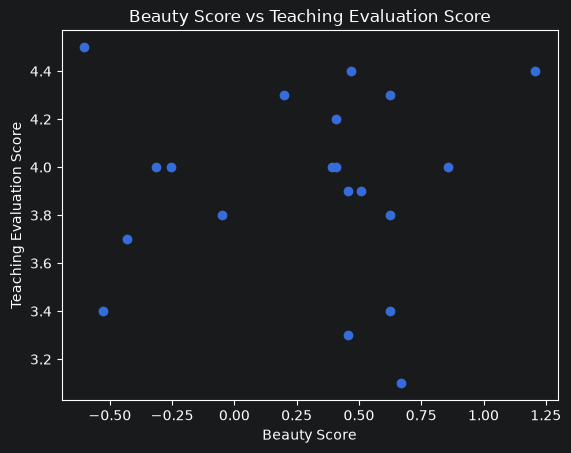

In [14]:
plt.scatter(df["beauty"], df["eval"])

plt.xlabel("Beauty Score")
plt.ylabel("Teaching Evaluation Score")
plt.title("Beauty Score vs Teaching Evaluation Score")

plt.show()